# EA3 — Comparación de datos climáticos: Medellín y Buenos Aires

**Autor/a:** Paula Andrea Celis Cano
**Pregunta guía:** ¿Qué similitudes y diferencias se observan en las variables climáticas de Medellín y Buenos Aires durante el mismo periodo?

Este notebook obtiene datos diarios de estaciones meteorológicas en una misma base (Meteostat), conserva 2023 como periodo común candidato y comprueba que exista cobertura suficiente antes de comparar. Las observaciones están asociadas a estaciones, por lo que describen esos puntos de medición y no cada barrio o toda la ciudad. La celda de validación detiene el análisis si no hay mediciones comunes suficientes; no recorta el periodo para forzar una coincidencia.


## A. Predicción y diseño

**Predicción previa:** espero que las temperaturas máximas medias mensuales de Medellín varíen menos a lo largo del año que las de Buenos Aires; espero también que la precipitación se concentre en distintos meses y que haya diferencias en el número de días lluviosos. Estas expectativas se contrastarán con los datos, sin asumir causalidad.

- **Periodo candidato:** 1 de enero a 31 de diciembre de 2023 (año calendario completo).
- **Frecuencia:** diaria.
- **Variables:** temperatura máxima (`tmax`, °C) y precipitación (`prcp`, mm/día).
- **Medellín:** estación Olaya Herrera, Meteostat ID `80110`.
- **Buenos Aires:** estación Ezeiza Aerodrome, Meteostat/WMO `87576`, ubicada en el aeropuerto en Ezeiza, que sirve al área metropolitana; representa esa estación y no un promedio espacial de Buenos Aires.
- **Umbral térmico común para las máscaras:** temperatura máxima > 25 °C. Día lluvioso: precipitación > 0 mm.

**Fuentes:** [Meteostat, estación Medellín/Olaya Herrera](https://meteostat.net/en/station/80110), [Meteostat, estación Ezeiza Aerodrome](https://meteostat.net/en/station/87576), [estación Ezeiza del Servicio Meteorológico Nacional argentino](https://w2b.smn.gov.ar/oapi/collections/stations/items/0-20000-0-87576?f=html), [documentación de datos diarios de Meteostat](https://dev.meteostat.net/data/timeseries/daily.html), [GHCN-Daily de NOAA/NCEI](https://www.ncei.noaa.gov/products/land-based-station/global-historical-climatology-network-daily). Los archivos diarios CSV por estación se sirven desde `https://bulk.meteostat.net/v2/daily/{ID}.csv.gz`; la base Meteostat compila observaciones de estaciones y puede integrar varias fuentes. El archivo diario de Meteostat puede incluir estimaciones para completar faltantes, según la documentación del proveedor; por ello, interpreta los valores como serie diaria compilada por Meteostat y revisa las marcas de fuente si necesitas distinguir observación de estimación. Revisa también los metadatos y cobertura que imprime el notebook al ejecutarlo.



## Preparación del entorno

Si este kernel no tiene instaladas las librerías, ejecuta la siguiente celda una vez y luego continúa con las importaciones. `%pip` instala en el entorno de Python asociado al notebook.


In [1]:
%pip install numpy pandas matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
from pathlib import Path
from urllib.request import urlopen
from io import BytesIO
import gzip
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

YEAR = 2023
START, END = f"{YEAR}-01-01", f"{YEAR}-12-31"
STATIONS = {"Medellín (Olaya Herrera)": "80110", "Buenos Aires (Ezeiza Aerodrome)": "87576"}


## B. Descarga, carga y revisión

La descarga queda guardada en `datos/` junto al notebook cuando se ejecuta. Cada tabla contiene una fila por fecha y los campos originales del proveedor. La temperatura máxima ya está en °C y la precipitación en mm, así que no se requiere conversión. La documentación de Meteostat indica que los campos diarios pueden estar vacíos cuando no hubo dato; esos valores permanecen como `NaN`.


In [3]:
data_dir = Path("datos")
data_dir.mkdir(exist_ok=True)

def load_station(name, station_id):
    url = f"https://bulk.meteostat.net/v2/daily/{station_id}.csv.gz"
    print(f"Descargando {name}: {url}")
    with urlopen(url, timeout=60) as response:
        raw = gzip.decompress(response.read())
    path = data_dir / f"{station_id}_daily.csv"
    path.write_bytes(raw)
    df = pd.read_csv(BytesIO(raw), header=None,
                     names=["date", "tavg", "tmin", "tmax", "prcp", "snow", "wdir", "wspd", "wpgt", "pres", "tsun"])
    df["date"] = pd.to_datetime(df["date"], errors="coerce")
    for col in ["tmax", "prcp"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")
    df = df.dropna(subset=["date"]).sort_values("date")
    print(f"Fuente: {url} | archivo local: {path}")
    print("Columnas:", df.columns.tolist(), "| dimensiones:", df.shape)
    print("Fechas observadas:", df.date.min().date(), "a", df.date.max().date())
    print("Faltantes por variable: \n", df[["tmax", "prcp"]].isna().sum())
    print("Fechas duplicadas:", int(df.date.duplicated().sum()))
    display(df.head())
    return df

raw_data = {name: load_station(name, sid) for name, sid in STATIONS.items()}


Descargando Medellín (Olaya Herrera): https://bulk.meteostat.net/v2/daily/80110.csv.gz
Fuente: https://bulk.meteostat.net/v2/daily/80110.csv.gz | archivo local: datos\80110_daily.csv
Columnas: ['date', 'tavg', 'tmin', 'tmax', 'prcp', 'snow', 'wdir', 'wspd', 'wpgt', 'pres', 'tsun'] | dimensiones: (16885, 11)
Fechas observadas: 1958-01-02 a 2026-03-28
Faltantes por variable: 
 tmax    9580
prcp    7443
dtype: int64
Fechas duplicadas: 0


,date,tavg,tmin,tmax,prcp,snow,wdir,wspd,wpgt,pres,tsun
0,1958-01-02,24.3,NaN,32.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1958-01-03,23.8,NaN,28.9,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1958-01-05,25.3,NaN,31.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1958-01-06,23.9,16.1,32.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1958-01-07,23.1,16.1,26.1,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Descargando Buenos Aires (Ezeiza Aerodrome): https://bulk.meteostat.net/v2/daily/87576.csv.gz
Fuente: https://bulk.meteostat.net/v2/daily/87576.csv.gz | archivo local: datos\87576_daily.csv
Columnas: ['date', 'tavg', 'tmin', 'tmax', 'prcp', 'snow', 'wdir', 'wspd', 'wpgt', 'pres', 'tsun'] | dimensiones: (20541, 11)
Fechas observadas: 1957-07-01 a 2026-03-19
Faltantes por variable: 
 tmax    4276
prcp    8699
dtype: int64
Fechas duplicadas: 0


,date,tavg,tmin,tmax,prcp,snow,wdir,wspd,wpgt,pres,tsun
0,1957-07-01,4.3,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1957-07-02,5.8,2.2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,1957-07-03,9.3,3.9,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,1957-07-04,11.0,5.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,1957-07-05,13.9,10.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Filtramos ambas tablas al mismo año predefinido. Se exige exactamente una fila por cada día del año en cada tabla; faltantes en las mediciones se reportan aparte y solo las fechas con ambas variables válidas en ambas estaciones entran en las comparaciones por pares.


In [4]:
daily = {}
expected_dates = pd.date_range(START, END, freq="D")
for name, df in raw_data.items():
    year_df = df[df.date.between(START, END)].copy()
    if year_df.date.duplicated().any():
        raise ValueError(f"Hay fechas duplicadas en {name}; resuelve duplicados antes del análisis.")
    year_df = year_df.set_index("date").reindex(expected_dates)
    year_df.index.name = "date"
    print(f"{name}: {len(year_df)} fechas del periodo; tmax faltante={year_df.tmax.isna().sum()}, prcp faltante={year_df.prcp.isna().sum()}")
    daily[name] = year_df

valid_masks = [d[["tmax", "prcp"]].notna().all(axis=1) for d in daily.values()]
common_dates = expected_dates[np.logical_and.reduce([m.to_numpy() for m in valid_masks])]
print("Días válidos en ambas ciudades para las dos variables:", len(common_dates), "de", len(expected_dates))
if len(common_dates) < 300:
    raise ValueError("Cobertura común insuficiente para representar el año: busca estaciones con mejor continuidad y documenta los nuevos IDs.")
paired = {name: d.loc[common_dates, ["tmax", "prcp"]] for name, d in daily.items()}


Medellín (Olaya Herrera): 365 fechas del periodo; tmax faltante=0, prcp faltante=0
Buenos Aires (Ezeiza Aerodrome): 365 fechas del periodo; tmax faltante=0, prcp faltante=0
Días válidos en ambas ciudades para las dos variables: 365 de 365


## C. Análisis con NumPy

Usamos arrays de fechas coincidentes para comparar los mismos días. Los cortes inspeccionan los primeros siete días disponibles. Las máscaras seleccionan días lluviosos y días con `tmax > 25 °C`; ambas reglas se aplican a las dos ciudades. `np.nan*` evita que valores faltantes fuera del subconjunto común alteren resúmenes, aunque aquí los arrays emparejados ya tienen datos completos.


In [5]:
arrays = {name: {"tmax": frame.tmax.to_numpy(dtype=float),
                    "prcp": frame.prcp.to_numpy(dtype=float)}
          for name, frame in paired.items()}
print("Primeros siete pares de fechas y temperaturas máximas:")
for name, frame in paired.items():
    print("\n", name)
    display(frame.head(7))

RAIN_THRESHOLD_MM = 0.0
TEMP_THRESHOLD_C = 25.0
summary = {}
for name, values in arrays.items():
    rainy = values["prcp"] > RAIN_THRESHOLD_MM
    hot = values["tmax"] > TEMP_THRESHOLD_C
    summary[name] = {
        "tmax_promedio_C": np.mean(values["tmax"]),
        "tmax_minimo_C": np.min(values["tmax"]),
        "tmax_maximo_C": np.max(values["tmax"]),
        "precipitacion_total_mm": np.sum(values["prcp"]),
        "dias_lluviosos": int(np.sum(rainy)),
        "dias_tmax_mayor_25C": int(np.sum(hot)),
    }
    print(f"{name}: máscara lluviosa={rainy.sum()} días; máscara tmax > {TEMP_THRESHOLD_C} °C={hot.sum()} días")
summary_df = pd.DataFrame(summary).T
summary_df.round(2)


Primeros siete pares de fechas y temperaturas máximas:

 Medellín (Olaya Herrera)


,tmax,prcp
date,,
2023-01-01,27.0,0.5
2023-01-02,28.0,5.1
2023-01-03,23.0,0.0
2023-01-04,28.0,0.5
2023-01-05,26.0,11.5
2023-01-06,26.0,13.1
2023-01-07,25.0,0.0



 Buenos Aires (Ezeiza Aerodrome)


,tmax,prcp
date,,
2023-01-01,33.6,6.8
2023-01-02,29.3,0.0
2023-01-03,32.3,0.0
2023-01-04,32.7,0.0
2023-01-05,33.1,0.0
2023-01-06,34.4,0.0
2023-01-07,34.8,0.0


Medellín (Olaya Herrera): máscara lluviosa=287 días; máscara tmax > 25.0 °C=334 días
Buenos Aires (Ezeiza Aerodrome): máscara lluviosa=117 días; máscara tmax > 25.0 °C=173 días


,tmax_promedio_C,tmax_minimo_C,tmax_maximo_C,precipitacion_total_mm,dias_lluviosos,dias_tmax_mayor_25C
Medellín (Olaya Herrera),28.39,22.0,32.0,2285.5,287.0,334.0
Buenos Aires (Ezeiza Aerodrome),24.72,10.3,39.6,855.3,117.0,173.0


### Broadcasting

Con NumPy broadcasting aplicamos a toda la matriz de precipitaciones por fecha la resta de la media de cada ciudad (un vector de longitud 2). El resultado expresa, por fecha, cuánto se apartó cada ciudad de su precipitación diaria media en los días emparejados. Es una transformación de centrado, no una prueba estadística de diferencias.


In [6]:
rain_matrix = np.column_stack([arrays[name]["prcp"] for name in STATIONS])
city_means = rain_matrix.mean(axis=0)
centered_rain = rain_matrix - city_means  # (n_dias, 2) - (2,) por broadcasting
print("Forma de la matriz:", rain_matrix.shape, "| forma de medias:", city_means.shape,
      "| forma centrada:", centered_rain.shape)
print("Medias diarias (mm):", dict(zip(STATIONS, city_means.round(2))))
print("Primeros tres días de precipitación centrada (mm):\n", centered_rain[:3].round(2))


Forma de la matriz: (365, 2) | forma de medias: (2,) | forma centrada: (365, 2)
Medias diarias (mm): {'Medellín (Olaya Herrera)': np.float64(6.26), 'Buenos Aires (Ezeiza Aerodrome)': np.float64(2.34)}
Primeros tres días de precipitación centrada (mm):
 [[-5.76  4.46]
 [-1.16 -2.34]
 [-6.26 -2.34]]


## D. Gráficas comparativas

### 1. Temperatura máxima mensual

Cada punto representa la media de las temperaturas máximas diarias disponibles en las fechas emparejadas del mes. La gráfica compara las estaciones y los meses incluidos en la muestra común.


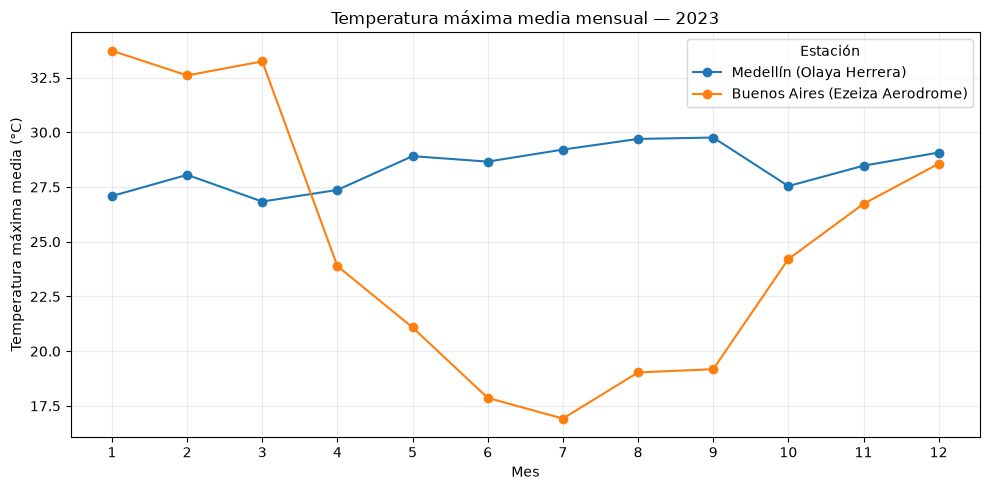

In [7]:
monthly_tmax = pd.DataFrame({name: frame.tmax for name, frame in paired.items()}).groupby(pd.Series(common_dates.month, index=common_dates)).mean()
monthly_tmax.index.name = "Mes"
ax = monthly_tmax.plot(marker="o", figsize=(10, 5))
ax.set(title="Temperatura máxima media mensual — 2023", xlabel="Mes", ylabel="Temperatura máxima media (°C)", xticks=range(1, 13))
ax.legend(title="Estación")
ax.grid(alpha=.25)
plt.tight_layout(); plt.show()


**Qué se observa:** Medellín se mantuvo relativamente estable, entre 26,84 y 29,76 °C. Ezeiza varió más: llegó a 33,73 °C en enero y bajó a 16,92 °C en julio. Un solo año no permite afirmar que ese patrón se repita ni explicar sus causas.

### 2. Precipitación acumulada mensual

La suma usa días con medición válida, dentro del conjunto común; los valores ausentes nunca se sustituyen por cero.


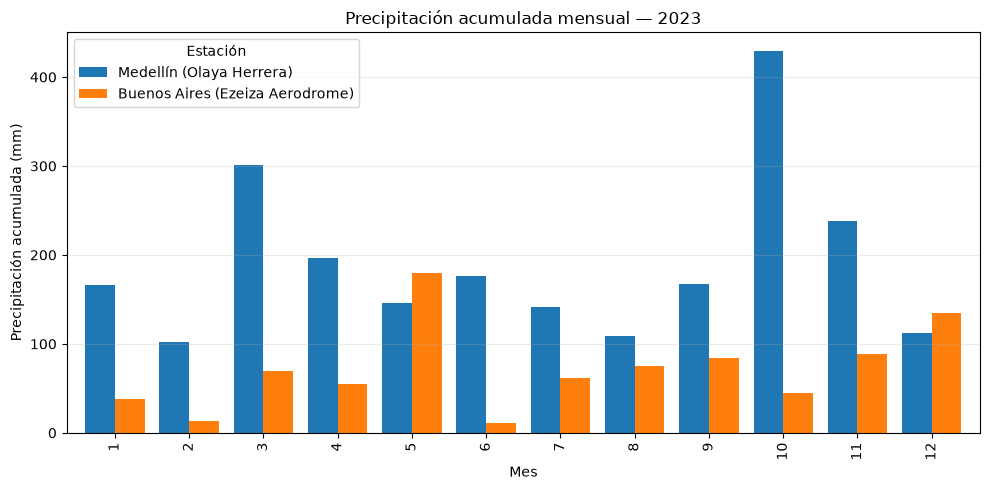

In [8]:
monthly_prcp = pd.DataFrame({name: frame.prcp for name, frame in paired.items()}).groupby(pd.Series(common_dates.month, index=common_dates)).sum(min_count=1)
monthly_prcp.index.name = "Mes"
ax = monthly_prcp.plot(kind="bar", figsize=(10, 5), width=.8)
ax.set(title="Precipitación acumulada mensual — 2023", xlabel="Mes", ylabel="Precipitación acumulada (mm)")
ax.legend(title="Estación")
ax.grid(axis="y", alpha=.25)
plt.tight_layout(); plt.show()


**Qué se observa:** los grupos de barras muestran cómo se distribuyó la lluvia reportada entre meses y ciudades.
**Qué no permite concluir:** una suma puede ser menor en meses con más datos faltantes; revisa la cantidad de días válidos mensual antes de interpretar diferencias como climáticas.
Octubre fue el mes más lluvioso en Medellín (428,8 mm) y mayo en Ezeiza (179,9 mm). Los perfiles mensuales fueron distintos; los datos de un solo año no indican por qué.



### 3. Distribución de temperatura máxima diaria

El histograma permite comparar la distribución completa de las temperaturas máximas observadas en los días emparejados.


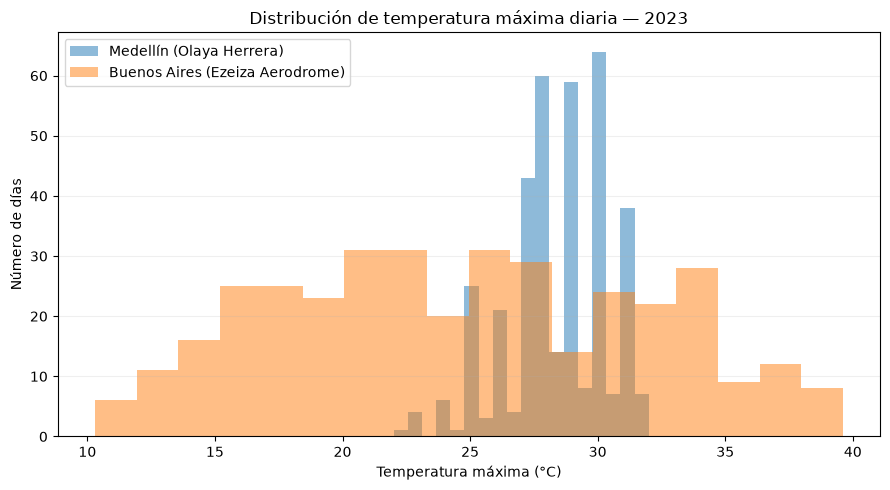

In [9]:
plt.figure(figsize=(9, 5))
for name in STATIONS:
    plt.hist(arrays[name]["tmax"], bins=18, alpha=.5, label=name)
plt.title("Distribución de temperatura máxima diaria — 2023")
plt.xlabel("Temperatura máxima (°C)"); plt.ylabel("Número de días")
plt.legend(); plt.grid(axis="y", alpha=.2); plt.tight_layout(); plt.show()


**Qué se observa:** Las temperaturas máximas de Medellín estuvieron en un rango más cálido; en Ezeiza abarcaron de 10,3 a 39,6 °C. El histograma no muestra cuándo ocurrieron ni explica sus causas.


In [10]:
# Número de días medidos por mes y estación, para contextualizar las sumas mensuales
monthly_coverage = pd.DataFrame({name: frame.prcp.notna().groupby(frame.index.month).sum() for name, frame in daily.items()})
monthly_coverage.index.name = "Mes"
monthly_coverage


,Medellín (Olaya Herrera),Buenos Aires (Ezeiza Aerodrome)
Mes,,
1,31,31
2,28,28
3,31,31
4,30,30
5,31,31
6,30,30
7,31,31
8,31,31
9,30,30


## E. Interpretación basada en resultados

La celda siguiente genera un borrador de cifras concretas para apoyar la redacción. Revisa las salidas de las gráficas y completa los dos hallazgos en tus palabras antes de entregar.


In [11]:
print("Resumen (mediciones en fechas válidas comunes):")
display(summary_df.round(2))
print("\nTemperatura máxima media mensual (°C):")
display(monthly_tmax.round(2))
print("\nPrecipitación mensual (mm):")
display(monthly_prcp.round(1))
print("\nDiferencia de temperatura máxima media anual (Medellín - Buenos Aires):",
      round(summary_df.loc["Medellín (Olaya Herrera)", "tmax_promedio_C"] - summary_df.loc["Buenos Aires (Ezeiza Aerodrome)", "tmax_promedio_C"], 2), "°C")


Resumen (mediciones en fechas válidas comunes):


,tmax_promedio_C,tmax_minimo_C,tmax_maximo_C,precipitacion_total_mm,dias_lluviosos,dias_tmax_mayor_25C
Medellín (Olaya Herrera),28.39,22.0,32.0,2285.5,287.0,334.0
Buenos Aires (Ezeiza Aerodrome),24.72,10.3,39.6,855.3,117.0,173.0



Temperatura máxima media mensual (°C):


,Medellín (Olaya Herrera),Buenos Aires (Ezeiza Aerodrome)
Mes,,
1,27.09,33.73
2,28.06,32.60
3,26.84,33.24
4,27.37,23.89
5,28.91,21.08
6,28.66,17.87
7,29.21,16.92
8,29.70,19.03
9,29.76,19.18



Precipitación mensual (mm):


,Medellín (Olaya Herrera),Buenos Aires (Ezeiza Aerodrome)
Mes,,
1,166.5,38.5
2,102.6,13.0
3,301.0,69.1
4,196.4,54.4
5,146.1,179.9
6,176.8,11.1
7,141.0,61.6
8,109.2,74.8
9,167.1,84.1



Diferencia de temperatura máxima media anual (Medellín - Buenos Aires): 3.67 °C


### Hallazgos y límites

1. **Similitud:** En las dos estaciones hubo días lluviosos en los 12 meses de 2023. Medellín registró 287 días lluviosos y Ezeiza, 117.
2. **Diferencia:** La temperatura máxima media fue 28,39 °C en Medellín y 24,72 °C en Ezeiza, una diferencia de 3,67 °C. La precipitación acumulada fue 2.285,5 mm y 855,3 mm, respectivamente. El mes más lluvioso fue octubre en Medellín (428,8 mm) y mayo en Ezeiza (179,9 mm).
3. **Cobertura y límites:** Se compararon 365 días de 2023. Aunque no hay faltantes en el periodo analizado, Meteostat puede completar vacíos con estimaciones; además, cada dato representa una estación, y un solo año no describe el clima de largo plazo.

**Respuesta a la pregunta  ¿Qué similitudes y diferencias se observan en las variables climáticas de Medellín y Buenos Aires durante el mismo periodo?** En 2023, ambas estaciones registraron lluvia en todos los meses, pero Medellín tuvo más días lluviosos y mayor precipitación acumulada. También presentó una temperatura máxima media más alta. Estos resultados describen las dos estaciones y el año analizado; no demuestran causas ni representan promedios de toda cada ciudad.
